<a href="https://colab.research.google.com/github/icy-agarwal/musical-instruments-recommender/blob/main/recommender.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!wget -O musical_instruments.json.gz "https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Musical_Instruments_5.json.gz"
!ls -lh

--2026-10-28 08:55:06--  https://mcauleylab.ucsd.edu/public_datasets/data/amazon_v2/categoryFilesSmall/Musical_Instruments_5.json.gz
Resolving mcauleylab.ucsd.edu (mcauleylab.ucsd.edu)... 137.110.161.5
Connecting to mcauleylab.ucsd.edu (mcauleylab.ucsd.edu)|137.110.161.5|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 39353085 (38M) [application/gzip]
Saving to: ‘musical_instruments.json.gz’

musical_instruments 100%[===================>]  37.53M  14.5MB/s    in 2.6s    

2026-10-28 08:55:09 (14.5 MB/s) - ‘musical_instruments.json.gz’ saved [39353085/39353085]

total 38M
-rw-r--r-- 1 root root  38M Jan 17  2025 musical_instruments.json.gz
drwxr-xr-x 1 root root 4.0K Oct 26 22:18 sample_data


In [2]:
import pandas as pd

df = pd.read_json("musical_instruments.json.gz", lines=True, compression="gzip")

print(df.shape)
print(df.columns.tolist())
df.head()

(231392, 12)
['overall', 'verified', 'reviewTime', 'reviewerID', 'asin', 'reviewerName', 'reviewText', 'summary', 'unixReviewTime', 'vote', 'style', 'image']


,overall,verified,reviewTime,reviewerID,asin,reviewerName,reviewText,summary,unixReviewTime,vote,style,image
0,5,True,"10 30, 2016",A3FO5AKVTFRCRJ,0739079891,francisco,It's good for beginners,Five Stars,1477785600,NaN,NaN,NaN
1,5,True,"06 30, 2016",A3UCGC1DHFMBCE,0739079891,Eb Jack Murray,I recommend this starter Ukulele kit. I has e...,Five Stars,1467244800,NaN,NaN,NaN
2,5,True,"05 9, 2016",A2S9SLRYLPGYZB,0739079891,Clara LaMarr,G'daughter received this for Christmas present...,Learning new songs to play regularly,1462752000,NaN,NaN,NaN
3,4,True,"04 10, 2016",A15RTJWPG8OKOE,0739079891,Eagle80,"According to my order history, I bought this t...",A bargain-bin good-enough ukulele that's held ...,1460246400,NaN,NaN,NaN
4,1,True,"02 6, 2016",A12ET1WO3OAVU7,0739079891,Amazon Customer,Please pay attention better than I did to the ...,Poor Quality product.,1454716800,NaN,NaN,NaN


In [3]:
df = df[["reviewerID", "asin", "overall", "unixReviewTime"]].copy()
df = df.rename(columns={
    "reviewerID": "user_id",
    "asin": "item_id",
    "overall": "rating",
    "unixReviewTime": "timestamp",
})
df["date"] = pd.to_datetime(df["timestamp"], unit="s")

print(df.shape)
print(df.isna().sum())
print(df["date"].min(), df["date"].max())
df.head()

(231392, 5)
user_id      0
item_id      0
rating       0
timestamp    0
date         0
dtype: int64
2003-10-28 00:00:00 2018-09-28 00:00:00


,user_id,item_id,rating,timestamp,date
0,A3FO5AKVTFRCRJ,0739079891,5,1477785600,2016-10-30
1,A3UCGC1DHFMBCE,0739079891,5,1467244800,2016-06-30
2,A2S9SLRYLPGYZB,0739079891,5,1462752000,2016-05-09
3,A15RTJWPG8OKOE,0739079891,4,1460246400,2016-04-10
4,A12ET1WO3OAVU7,0739079891,1,1454716800,2016-02-06


In [4]:
n_users = df["user_id"].nunique()
n_items = df["item_id"].nunique()
n_ratings = len(df)

print("users:", n_users)
print("items:", n_items)
print("ratings:", n_ratings)
print(df["rating"].value_counts().sort_index())

users: 27530
items: 10620
ratings: 231392
rating
1      7465
2      7277
3     16030
4     38783
5    161837
Name: count, dtype: int64


In [5]:
sparsity = 1-n_ratings/(n_users*n_items)
print("sparsity = ", sparsity*100)

sparsity =  99.92085607004309


In [6]:
ratings_per_user = df.groupby("user_id").size()
ratings_per_item = df.groupby("item_id").size()

print(ratings_per_user.describe())
print(ratings_per_item.describe())

count    27530.000000
mean         8.405085
std          6.261999
min          3.000000
25%          5.000000
50%          6.000000
75%          9.000000
max        264.000000
dtype: float64
count    10620.000000
mean        21.788324
std         62.696075
min          1.000000
25%          6.000000
50%          9.000000
75%         18.000000
max       1880.000000
dtype: float64


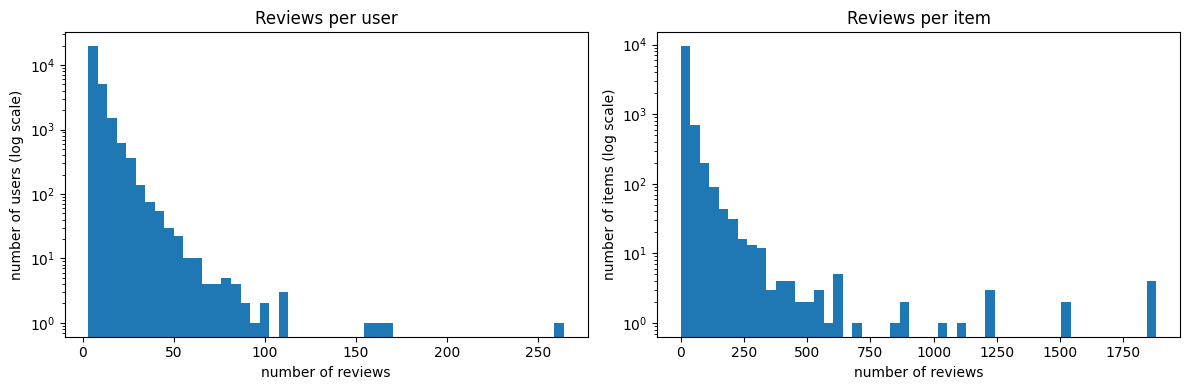

In [7]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(ratings_per_user, bins=50, log=True)
axes[0].set_title("Reviews per user")
axes[0].set_xlabel("number of reviews")
axes[0].set_ylabel("number of users (log scale)")

axes[1].hist(ratings_per_item, bins=50, log=True)
axes[1].set_title("Reviews per item")
axes[1].set_xlabel("number of reviews")
axes[1].set_ylabel("number of items (log scale)")

plt.tight_layout()
plt.show()

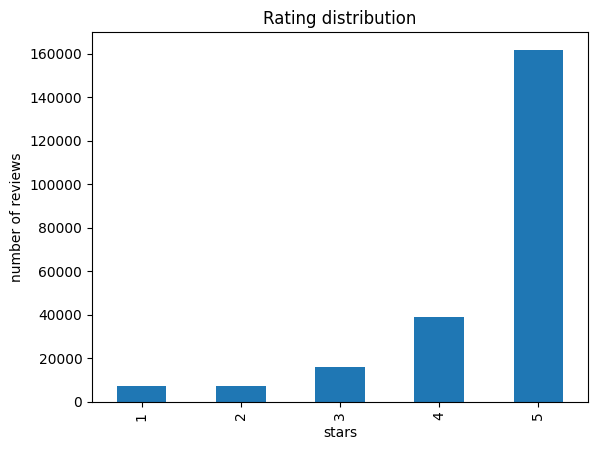

In [8]:
df["rating"].value_counts().sort_index().plot(kind="bar")
plt.xlabel("stars")
plt.ylabel("number of reviews")
plt.title("Rating distribution")
plt.show()

In [9]:
n_dups = df.duplicated(subset=["user_id", "item_id"]).sum()
print("duplicate (user, item) pairs:", n_dups)

duplicate (user, item) pairs: 12236


In [10]:
dup_rows = df[df.duplicated(subset=["user_id", "item_id"], keep=False)]
dup_rows = dup_rows.sort_values(["user_id", "item_id", "timestamp"])
dup_rows.head(10)

,user_id,item_id,rating,timestamp,date
80315,A0072193KFP6LUHKEXLT,B000VSM4MS,2,1374364800,2013-07-21
89081,A0072193KFP6LUHKEXLT,B000VSM4MS,2,1374364800,2013-07-21
85922,A0096681Y127OL1H8W3U,B0014WWNUS,5,1437091200,2015-07-17
94688,A0096681Y127OL1H8W3U,B0014WWNUS,5,1437091200,2015-07-17
103172,A0279100VZXR9A2495P4,B001LNN2E6,5,1363564800,2013-03-18
103171,A0279100VZXR9A2495P4,B001LNN2E6,5,1368316800,2013-05-12
83108,A0600727NK5MAF66IOY5,B000Z7567A,5,1395619200,2014-03-24
91874,A0600727NK5MAF66IOY5,B000Z7567A,5,1395619200,2014-03-24
87710,A0833006NJW9KRF77ZFY,B00178JDCK,5,1368316800,2013-05-12
96476,A0833006NJW9KRF77ZFY,B00178JDCK,5,1368316800,2013-05-12


In [11]:
before = len(df)

df = df.sort_values("timestamp")
df = df.drop_duplicates(subset=["user_id", "item_id"], keep="last")

print("rows before:", before)
print("rows after:", len(df))
print("rows removed:", before - len(df))

rows before: 231392
rows after: 219156
rows removed: 12236


In [12]:
k = 5

while True:
    user_counts = df["user_id"].value_counts()
    item_counts = df["item_id"].value_counts()
    keep = (df["user_id"].map(user_counts) >= k) & (df["item_id"].map(item_counts) >= k)
    if keep.all():
        break
    df = df[keep]

print("shape:", df.shape)
print("users:", df["user_id"].nunique(), "items:", df["item_id"].nunique())
print("min reviews per user:", df["user_id"].value_counts().min())
print("min reviews per item:", df["item_id"].value_counts().min())

shape: (206241, 5)
users: 24780 items: 9930
min reviews per user: 5
min reviews per item: 5


In [13]:
df["year"] = df["date"].dt.year
print(df["year"].value_counts().sort_index())

year
2003        1
2004       43
2005       43
2006       77
2007      175
2008      367
2009      784
2010     1860
2011     4224
2012     7588
2013    18535
2014    31620
2015    44332
2016    46218
2017    35887
2018    14487
Name: count, dtype: int64


In [14]:
train = df[df["date"] < "2017-01-01"]
val = df[(df["date"] >= "2017-01-01") & (df["date"] < "2018-01-01")]
test = df[df["date"] >= "2018-01-01"]

print("train:", len(train), "val:", len(val), "test:", len(test))
print("users in val:", val["user_id"].nunique())
print("val users NOT in train:", len(set(val["user_id"]) - set(train["user_id"])))
print("users in test:", test["user_id"].nunique())
print("test users NOT in train:", len(set(test["user_id"]) - set(train["user_id"])))

train: 155867 val: 35887 test: 14487
users in val: 10146
val users NOT in train: 2076
users in test: 5258
test users NOT in train: 1255


In [15]:
for name, part in [("val", val), ("test", test)]:
    print(name, "share with rating >= 4:", (part["rating"] >= 4).mean())
    print(name, "share with rating == 5:", (part["rating"] == 5).mean())

val share with rating >= 4: 0.867082787638978
val share with rating == 5: 0.7108423663164934
test share with rating >= 4: 0.8531096845447643
test share with rating == 5: 0.7011113412024573


# Evaluation protocol

## 1. Dataset
- Amazon Review Data (2018), Musical Instruments, 5-core file (UCSD, Jianmo Ni).
- Original file: 231,392 reviews. Kept only user ID, item ID, rating and timestamp.
- Removed 12,236 duplicate (user, item) pairs, keeping the most recent review.
- Re-applied an iterative 5-core filter (every user and item has at least 5 reviews).
- Final data: 206,241 reviews, 24,780 users, 9,930 items.

## 2. Split (by time, never random)
- Train: reviews before 2017-01-01 (155,867 reviews)
- Validation: 2017 (35,887 reviews)
- Test: 2018, up to September (14,487 reviews)
- Models are tuned on validation. The test set is used once at the end.

## 3. What counts as a hit
- A recommended item is a hit if the user later reviewed it with a rating of 4 or 5.
- Note: the data is heavily positive (about 85-87% of reviews are 4 or 5 stars), so this rule is lenient.

## 4. Metrics
- Precision@10, recall@10 and catalog coverage, with k = 10.
- Every model is compared against a popularity baseline.

## 5. Rules
- Recommendations never include items the user has already reviewed.
- Evaluation covers only users who have history in train.
- Users with no train history are reported separately: about 20% of validation users (2,076 of 10,146) and about 24% of test users (1,255 of 5,258). They need a cold-start fallback.

## 6. Limitations
- Reviews are a stand-in for purchases. Many buyers do not leave reviews.
- The data ends in September 2018.
- Dollar ($) figures in the churn part are assumptions, not real business results.

In [16]:
from google.colab import drive
drive.mount("/content/drive")

import os
folder = "/content/drive/MyDrive/recsys_project"
os.makedirs(folder, exist_ok=True)

cols = ["user_id", "item_id", "rating", "timestamp"]
train[cols].to_csv(folder + "/train.csv", index=False)
val[cols].to_csv(folder + "/val.csv", index=False)
test[cols].to_csv(folder + "/test.csv", index=False)

print(os.listdir(folder))

Mounted at /content/drive
['train.csv', 'val.csv', 'test.csv']


In [17]:
def precision_recall_at_k(recommended, relevant, k=10):
    recommended = recommended[:k]
    hits = len(set(recommended) & set(relevant))
    precision = hits / k
    recall = hits / len(relevant) if len(relevant) > 0 else 0
    return precision, recall

# test: 10 recommendations, 2 of them right, user liked 4 products in total
recommended = ["a", "b", "c", "d", "e", "f", "g", "h", "i", "j"]
relevant = ["a", "b", "x", "y"]
print(precision_recall_at_k(recommended, relevant))

(0.2, 0.5)


In [18]:
popular_items = train["item_id"].value_counts().index.tolist()
train_seen = train.groupby("user_id")["item_id"].apply(set).to_dict()
val_relevant = val[val["rating"] >= 4].groupby("user_id")["item_id"].apply(set).to_dict()
val_users = [u for u in val_relevant if u in train_seen]

print("top 3 popular items:", popular_items[:3])
print("val users with at least one liked item:", len(val_relevant))
print("of those, users with train history:", len(val_users))

top 3 popular items: ['B0002H03YY', 'B0006LOBA8', 'B0002H05BA']
val users with at least one liked item: 9457
of those, users with train history: 7424


In [19]:
def recommend_popular(user_id, k=10):
    seen = train_seen.get(user_id, set())
    recs = []
    for item in popular_items:
        if item not in seen:
            recs.append(item)
        if len(recs) == k:
            break
    return recs

precisions, recalls = [], []
all_recommended = set()

for u in val_users:
    recs = recommend_popular(u)
    p, r = precision_recall_at_k(recs, val_relevant[u])
    precisions.append(p)
    recalls.append(r)
    all_recommended.update(recs)

print("precision@10:", sum(precisions) / len(precisions))
print("recall@10:", sum(recalls) / len(recalls))
print("coverage:", len(all_recommended) / train["item_id"].nunique())

precision@10: 0.013698814655172415
recall@10: 0.02950182894723273
coverage: 0.0023522192677439147


In [20]:
import numpy as np
from scipy.sparse import csr_matrix

users = train["user_id"].unique()
items = train["item_id"].unique()
user_index = {u: i for i, u in enumerate(users)}
item_index = {it: j for j, it in enumerate(items)}

rows = train["user_id"].map(user_index).values
cols = train["item_id"].map(item_index).values
vals = train["rating"].values.astype(float)

R = csr_matrix((vals, (rows, cols)), shape=(len(users), len(items)))
print("shape:", R.shape)
print("filled cells:", R.nnz)

shape: (22215, 9778)
filled cells: 155867


In [21]:
from sklearn.preprocessing import normalize
Rn = normalize(R, norm="l2", axis=1)

u = val_users[0]
ui = user_index[u]

sims = (Rn @ Rn[ui].T).toarray().ravel()
sims[ui] = 0
top = np.argsort(sims)[::-1][:5]

print("this user reviewed", len(train_seen[u]), "products in train")
print("users sharing at least one product with them:", (sims > 0).sum())
print("top 5 most similar users (row number, similarity):")
for j in top:
    print(j, round(sims[j], 3))

this user reviewed 33 products in train
users sharing at least one product with them: 1352
top 5 most similar users (row number, similarity):
8503 0.359
22130 0.269
13168 0.258
21879 0.254
21428 0.254


In [22]:
k = 50
top_k = np.argsort(sims)[::-1][:k]
w = np.zeros(len(users))
w[top_k] = sims[top_k]

scores = R.T @ w
seen_idx = [item_index[i] for i in train_seen[u]]
scores[seen_idx] = -1

best = np.argsort(scores)[::-1][:10]
recs = items[best].tolist()

print("recommendations:", recs)
print("scores:", np.round(scores[best], 2))
print("liked in validation:", val_relevant[u])
print("precision, recall:", precision_recall_at_k(recs, val_relevant[u]))

recommendations: ['B003YUCU7O', 'B0006LXW9E', 'B005CX4GLE', 'B005FQO13Q', 'B0016H8S1O', 'B004UDM37Q', 'B001FDBUIW', 'B0002F7290', 'B0002F741Q', 'B0002E2OTE']
scores: [4.13 2.52 2.48 2.07 1.8  1.8  1.8  1.64 1.58 1.56]
liked in validation: {'B000CD1R7K', 'B0002OMOGC', 'B004MW5B8I', 'B0075DO5K6', 'B0002D0J4C', 'B000EEJ3S2'}
precision, recall: (0.0, 0.0)


In [23]:
import time

def recommend_user_cf(u, k=50, n=10):
    ui = user_index[u]
    sims = (Rn @ Rn[ui].T).toarray().ravel()
    sims[ui] = 0
    top_k = np.argsort(sims)[::-1][:k]
    w = np.zeros(len(users))
    w[top_k] = sims[top_k]
    scores = R.T @ w
    scores[[item_index[i] for i in train_seen[u]]] = -1
    best = np.argsort(scores)[::-1][:n]
    return items[best].tolist()

def evaluate(recommend_fn, user_list, relevant, k=10):
    ps, rs, shown = [], [], set()
    for u in user_list:
        recs = recommend_fn(u)
        p, r = precision_recall_at_k(recs, relevant[u], k)
        ps.append(p)
        rs.append(r)
        shown.update(recs)
    return sum(ps) / len(ps), sum(rs) / len(rs), len(shown) / len(items)

start = time.time()
print("popularity :", evaluate(recommend_popular, val_users, val_relevant))
print("user-based :", evaluate(recommend_user_cf, val_users, val_relevant))
print("seconds:", round(time.time() - start))

popularity : (0.013698814655172415, 0.02950182894723273, 0.0023522192677439147)
user-based : (0.00816271551724138, 0.02650128380907881, 0.6079975455103294)
seconds: 37


In [24]:
for kk in [10, 25, 50, 100, 200, 500]:
    res = evaluate(lambda u: recommend_user_cf(u, k=kk), val_users, val_relevant)
    print(kk, [round(x, 4) for x in res])

10 [0.0033, 0.0124, 0.8121]
25 [0.0054, 0.0184, 0.7582]
50 [0.0082, 0.0265, 0.608]
100 [0.01, 0.0324, 0.4714]
200 [0.0108, 0.0335, 0.4291]
500 [0.012, 0.0353, 0.4214]


In [25]:
for kk in [1000, 2000]:
    res = evaluate(lambda u: recommend_user_cf(u, k=kk), val_users, val_relevant)
    print(kk, [round(x, 4) for x in res])

1000 [0.0122, 0.0355, 0.4214]
2000 [0.0125, 0.0361, 0.4214]


In [26]:
Ri = normalize(R.T.tocsr(), norm="l2", axis=1)
S = (Ri @ Ri.T).tocsr()
S.setdiag(0)
S.eliminate_zeros()

print("shape:", S.shape)
print("non-empty cells:", S.nnz)
print("memory in MB:", round((S.data.nbytes + S.indices.nbytes + S.indptr.nbytes) / 1e6))

shape: (9778, 9778)
non-empty cells: 1311122
memory in MB: 16


In [27]:
def recommend_item_cf(u, n=10):
    ui = user_index[u]
    scores = (S @ R[ui].T).toarray().ravel()
    scores[[item_index[i] for i in train_seen[u]]] = -1
    best = np.argsort(scores)[::-1][:n]
    return items[best].tolist()

print("item-based :", evaluate(recommend_item_cf, val_users, val_relevant))

item-based : (0.004606681034482759, 0.015890736003673953, 0.9149110247494375)


In [28]:
for name, fn in [("popularity", recommend_popular),
                 ("user-CF k=500", lambda u: recommend_user_cf(u, k=500)),
                 ("item-CF", recommend_item_cf)]:
    t = time.time()
    evaluate(fn, val_users, val_relevant)
    print(name, "seconds:", round(time.time() - t, 1))

popularity seconds: 0.0
user-CF k=500 seconds: 32.2
item-CF seconds: 47.7


In [29]:
!pip install scikit-surprise

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 20.8 MB/s  0:00:00


In [30]:
from surprise import Dataset, Reader, SVD

reader = Reader(rating_scale=(1, 5))
trainset = Dataset.load_from_df(train[["user_id", "item_id", "rating"]], reader).build_full_trainset()

algo = SVD(n_factors=50, n_epochs=20, random_state=0)
algo.fit(trainset)

print("trained. users:", trainset.n_users, "items:", trainset.n_items)

trained. users: 22215 items: 9778


In [31]:
def recommend_svd(u, n=10):
    inner_u = trainset.to_inner_uid(u)
    scores = trainset.global_mean + algo.bu[inner_u] + algo.bi + algo.qi @ algo.pu[inner_u]
    seen = [trainset.to_inner_iid(i) for i in train_seen[u]]
    scores[seen] = -np.inf
    best = np.argsort(scores)[::-1][:n]
    return [trainset.to_raw_iid(i) for i in best]

print("SVD :", evaluate(recommend_svd, val_users, val_relevant))

SVD : (0.0014816810344827585, 0.004692830591941583, 0.09439558191859276)


In [32]:
preds = np.array([algo.predict(u, i).est for u, i in zip(val["user_id"], val["item_id"])])
actual = val["rating"].values

rmse_svd = np.sqrt(np.mean((preds - actual) ** 2))
rmse_mean = np.sqrt(np.mean((train["rating"].mean() - actual) ** 2))

print("RMSE SVD:", round(rmse_svd, 4))
print("RMSE always-guess-the-average:", round(rmse_mean, 4))

RMSE SVD: 0.9694
RMSE always-guess-the-average: 1.0027


In [33]:
def make_svd_recommender(model):
    def rec(u, n=10):
        inner_u = trainset.to_inner_uid(u)
        scores = trainset.global_mean + model.bu[inner_u] + model.bi + model.qi @ model.pu[inner_u]
        seen = [trainset.to_inner_iid(i) for i in train_seen[u]]
        scores[seen] = -np.inf
        best = np.argsort(scores)[::-1][:n]
        return [trainset.to_raw_iid(i) for i in best]
    return rec

for nf in [20, 50, 100]:
    for reg in [0.02, 0.1]:
        m = SVD(n_factors=nf, n_epochs=20, reg_all=reg, random_state=0)
        m.fit(trainset)
        p = np.array([m.predict(u, i).est for u, i in zip(val["user_id"], val["item_id"])])
        rmse = np.sqrt(np.mean((p - actual) ** 2))
        ranking = evaluate(make_svd_recommender(m), val_users, val_relevant)
        print(nf, reg, "RMSE", round(rmse, 4), "ranking", [round(x, 4) for x in ranking])

20 0.02 RMSE 0.9685 ranking [0.0017, 0.0051, 0.0363]
20 0.1 RMSE 0.9676 ranking [0.0008, 0.0029, 0.0278]
50 0.02 RMSE 0.9694 ranking [0.0015, 0.0047, 0.0944]
50 0.1 RMSE 0.968 ranking [0.0007, 0.003, 0.0854]
100 0.02 RMSE 0.9721 ranking [0.0013, 0.0041, 0.2081]
100 0.1 RMSE 0.9697 ranking [0.0005, 0.0019, 0.2009]


# Validation results (7,424 users with train history)

| Model | Precision@10 | Recall@10 | Coverage |
|---|---|---|---|
| Popularity | 0.0137 | 0.0295 | 0.0024 |
| User-CF (k=500) | 0.0120 | 0.0353 | 0.4214 |
| Item-CF | 0.0046 | 0.0159 | 0.9149 |
| SVD (20 factors, reg 0.02) | 0.0017 | 0.0051 | 0.0363 |

Notes
- Popularity is hardest to beat on precision. User-CF has the best recall.
- Item-CF and SVD recommend a much wider range of products but are less accurate.
- SVD RMSE is 0.9685 vs 1.0027 for always guessing the average, so it predicts ratings a little better than a guess but ranks poorly.
- Stronger regularization kept RMSE flat but cut precision@10 by half or more.
- Settings chosen on validation: user-CF k=500; SVD 20 factors, reg 0.02, 20 epochs.
- The test set has not been used yet.

In [34]:
print("sizes (should be 155867 35887 14487):", len(train), len(val), len(test))

full = pd.concat([train, val])
full_seen = full.groupby("user_id")["item_id"].apply(set).to_dict()
test_relevant = test[test["rating"] >= 4].groupby("user_id")["item_id"].apply(set).to_dict()
test_users = [u for u in test_relevant if u in full_seen]

print("full size:", len(full))
print("test users with at least one liked item:", len(test_relevant))
print("of those, users with history before 2018:", len(test_users))

sizes (should be 155867 35887 14487): 155867 35887 14487
full size: 191754
test users with at least one liked item: 4736
of those, users with history before 2018: 4249


In [35]:
train_seen = full_seen
popular_items = full["item_id"].value_counts().index.tolist()

users = full["user_id"].unique()
items = full["item_id"].unique()
user_index = {u: i for i, u in enumerate(users)}
item_index = {it: j for j, it in enumerate(items)}

R = csr_matrix((full["rating"].values.astype(float),
                (full["user_id"].map(user_index).values,
                 full["item_id"].map(item_index).values)),
               shape=(len(users), len(items)))
Rn = normalize(R, norm="l2", axis=1)

Ri = normalize(R.T.tocsr(), norm="l2", axis=1)
S = (Ri @ Ri.T).tocsr()
S.setdiag(0)
S.eliminate_zeros()

reader = Reader(rating_scale=(1, 5))
trainset = Dataset.load_from_df(full[["user_id", "item_id", "rating"]], reader).build_full_trainset()
algo = SVD(n_factors=20, n_epochs=20, reg_all=0.02, random_state=0)
algo.fit(trainset)

print("rebuilt. users:", len(users), "items:", len(items), "filled cells:", R.nnz)

rebuilt. users: 24291 items: 9924 filled cells: 191754


In [36]:
results = {}
for name, fn in [("popularity", recommend_popular),
                 ("user-CF k=500", lambda u: recommend_user_cf(u, k=500)),
                 ("item-CF", recommend_item_cf),
                 ("SVD 20 factors", recommend_svd)]:
    results[name] = evaluate(fn, test_users, test_relevant)
    print(name, [round(x, 4) for x in results[name]])

popularity [0.0102, 0.0237, 0.002]
user-CF k=500 [0.0093, 0.0307, 0.2401]
item-CF [0.0038, 0.0146, 0.8134]
SVD 20 factors [0.0012, 0.0038, 0.034]


In [37]:
def per_user(recommend_fn, user_list, relevant, k=10):
    rows = []
    for u in user_list:
        recs = recommend_fn(u)
        p, r = precision_recall_at_k(recs, relevant[u], k)
        rows.append((u, p, r))
    return pd.DataFrame(rows, columns=["user_id", "precision", "recall"]).set_index("user_id")

models = {"popularity": recommend_popular,
          "user-CF": lambda u: recommend_user_cf(u, k=500),
          "item-CF": recommend_item_cf,
          "SVD": recommend_svd}

counts = pd.Series({u: len(full_seen[u]) for u in test_users})
group = pd.cut(counts, bins=[0, 5, 10, np.inf], labels=["light 1-5", "medium 6-10", "heavy 11+"])
print(group.value_counts().sort_index())

table = {}
for name, fn in models.items():
    d = per_user(fn, test_users, test_relevant)
    table[name] = d["precision"].groupby(group, observed=False).mean()
print(pd.DataFrame(table).round(4))

light 1-5      2186
medium 6-10    1243
heavy 11+       820
Name: count, dtype: int64
             popularity  user-CF  item-CF     SVD
light 1-5        0.0146   0.0118   0.0036  0.0015
medium 6-10      0.0057   0.0071   0.0036  0.0010
heavy 11+        0.0052   0.0059   0.0046  0.0007


In [38]:
def build_state(data):
    st = {}
    st["train_seen"] = data.groupby("user_id")["item_id"].apply(set).to_dict()
    st["popular_items"] = data["item_id"].value_counts().index.tolist()
    st["users"] = data["user_id"].unique()
    st["items"] = data["item_id"].unique()
    st["user_index"] = {u: i for i, u in enumerate(st["users"])}
    st["item_index"] = {it: j for j, it in enumerate(st["items"])}
    st["R"] = csr_matrix((data["rating"].values.astype(float),
                          (data["user_id"].map(st["user_index"]).values,
                           data["item_id"].map(st["item_index"]).values)),
                         shape=(len(st["users"]), len(st["items"])))
    st["Rn"] = normalize(st["R"], norm="l2", axis=1)
    Ri = normalize(st["R"].T.tocsr(), norm="l2", axis=1)
    S = (Ri @ Ri.T).tocsr()
    S.setdiag(0)
    S.eliminate_zeros()
    st["S"] = S
    ts = Dataset.load_from_df(data[["user_id", "item_id", "rating"]], Reader(rating_scale=(1, 5))).build_full_trainset()
    st["trainset"] = ts
    st["algo"] = SVD(n_factors=20, n_epochs=20, reg_all=0.02, random_state=0).fit(ts)
    return st

names = ["train_seen", "popular_items", "users", "items", "user_index", "item_index", "R", "Rn", "S", "trainset", "algo"]
state_full = {n: globals()[n] for n in names}
globals().update(build_state(train))

counts_v = pd.Series({u: len(train_seen[u]) for u in val_users})
group_v = pd.cut(counts_v, bins=[0, 5, 10, np.inf], labels=["light 1-5", "medium 6-10", "heavy 11+"])
print(group_v.value_counts().sort_index())

per = {}
table = {}
for name, fn in models.items():
    d = per_user(fn, val_users, val_relevant)
    per[name] = d
    table[name] = d["precision"].groupby(group_v, observed=False).mean()
print(pd.DataFrame(table).round(4))

print("cutoff c: popularity if history <= c, else user-CF   (precision, recall)")
for c in [2, 3, 4, 5, 6, 8, 10]:
    use_pop = (counts_v <= c).values
    prec = np.where(use_pop, per["popularity"]["precision"].values, per["user-CF"]["precision"].values).mean()
    rec = np.where(use_pop, per["popularity"]["recall"].values, per["user-CF"]["recall"].values).mean()
    print(c, round(prec, 4), round(rec, 4))

globals().update(state_full)
print("restored full models, filled cells:", R.nnz)

light 1-5      4522
medium 6-10    1799
heavy 11+      1103
Name: count, dtype: int64
             popularity  user-CF  item-CF     SVD
light 1-5        0.0154   0.0132   0.0041  0.0017
medium 6-10      0.0098   0.0096   0.0036  0.0012
heavy 11+        0.0131   0.0111   0.0083  0.0024
cutoff c: popularity if history <= c, else user-CF   (precision, recall)
2 0.0139 0.0385
3 0.0137 0.0365
4 0.0133 0.0329
5 0.0133 0.0322
6 0.0136 0.0319
8 0.0134 0.0305
10 0.0134 0.03
restored full models, filled cells: 191754


In [39]:
def recommend_hybrid(u):
    if len(train_seen[u]) <= 2:
        return recommend_popular(u)
    return recommend_user_cf(u, k=500)

hy = evaluate(recommend_hybrid, test_users, test_relevant)
print("hybrid (cutoff 2):", [round(x, 4) for x in hy])
print("popularity       :", [round(x, 4) for x in results["popularity"]])
print("user-CF k=500    :", [round(x, 4) for x in results["user-CF k=500"]])

hybrid (cutoff 2): [0.0108, 0.0334, 0.1561]
popularity       : [0.0102, 0.0237, 0.002]
user-CF k=500    : [0.0093, 0.0307, 0.2401]


# Final test results (2018, 4,249 users with history before 2018)

| Model | Precision@10 | Recall@10 | Coverage |
|---|---|---|---|
| Popularity | 0.0102 | 0.0237 | 0.0020 |
| User-CF (k=500) | 0.0093 | 0.0307 | 0.2401 |
| Item-CF | 0.0038 | 0.0146 | 0.8134 |
| SVD (20 factors) | 0.0012 | 0.0038 | 0.0340 |
| Hybrid (popularity if <=2 reviews, else user-CF) | 0.0108 | 0.0334 | 0.1561 |

Notes
- Models were tuned on validation (2017), then rebuilt on train + validation and scored once on the 2018 test set.
- The hybrid cutoff (2 reviews) was chosen on validation, then scored on test once.
- Popularity is a strong baseline on this sparse, positive-skewed data. Hybrid recall is 41% above popularity; precision is comparable.
- User-CF and the hybrid recommend a wider range of products. Item-CF has the highest coverage but low accuracy.
- SVD predicts ratings slightly better than guessing the average (RMSE 0.969 vs 1.003 on validation) but ranks poorly.
- A breakdown by user activity on test suggested user-CF helps users with 6+ reviews, but this did not repeat on validation, so it is not claimed.
- About 10% of test users (487) are new with no history. They would get popularity and were not scored.
- Reviews are a stand-in for purchases, and the data ends in September 2018.